## Konversi ADC -> Salinitas (ppt)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Data pengambilan sampel
# ADC = nilai ADC dari sensor salinitas + DMS
# ppt = nilai salinitas dari sensor manual (hidrometer)

adc = np.array([623, 662, 685, 695, 700, 709, 713, 719, 722, 724, 726, 728, 730, 732, 734])
ppt = np.array([1, 2.5, 4, 6, 7.5, 10, 11, 13, 14.5, 16, 18, 20, 22, 23.5, 25.5])

In [2]:
# cubic regression
model = np.polyfit(adc - adc[-1], ppt, 3)
a, b, c, d = model

# evaluation
predicted = np.polyval(model, adc - adc[-1])
error = ppt - predicted

rmse = np.sqrt(np.mean(error ** 2))
mae = np.mean(np.abs(error))
r2 = 1 - np.sum(error ** 2) / np.sum((ppt - np.mean(ppt)) ** 2)

def adc_to_ppt(value):
    if value < adc[0]:
        return None

    if value <= adc[-1]:
        return float(np.interp(value, adc, ppt))

    x = value - adc[-1]
    return float(25.5 + a*(x**3) + b*(x**2) + c*x)

RMSE      : 0.714558 ppt
MAE       : 0.602921 ppt
Max Error : 1.280736 ppt
R^2       : 0.991097

ppt = 25.5 + (0.881884625156)x + (0.011977775148)x^2 + (0.000053787870)x^3


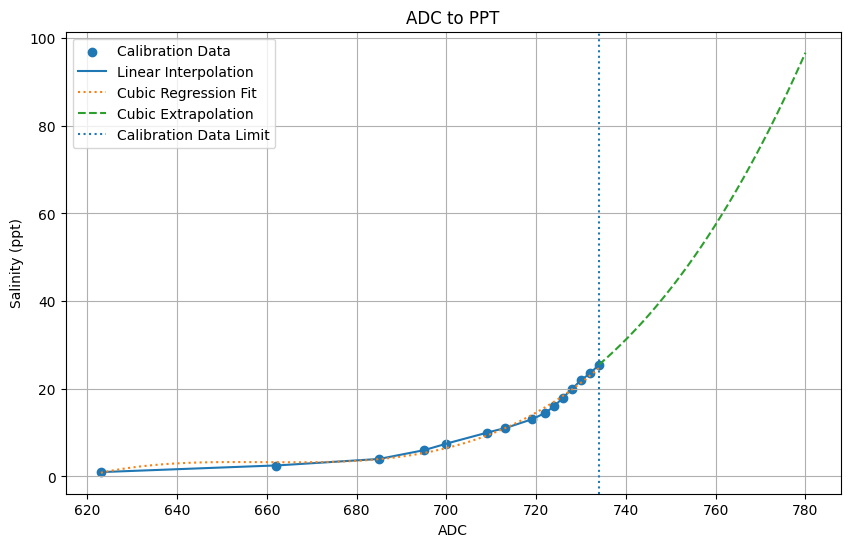

In [4]:
print(f"RMSE      : {rmse:.6f} ppt")
print(f"MAE       : {mae:.6f} ppt")
print(f"Max Error : {np.max(np.abs(error)):.6f} ppt")
print(f"R^2       : {r2:.6f}\n")
print(f"ppt = 25.5 + ({c:.12f})x + ({b:.12f})x^2 + ({a:.12f})x^3")

x_fit = np.linspace(adc[0], adc[-1], 300)
x_extra = np.linspace(adc[-1], 780, 200)

plt.figure(figsize=(10, 6))
plt.scatter(adc, ppt, label="Calibration Data")
plt.plot(x_fit, np.interp(x_fit, adc, ppt), label="Linear Interpolation")
plt.plot(x_fit, np.polyval(model, x_fit - adc[-1]), ":", label="Cubic Regression Fit")
plt.plot(x_extra, [adc_to_ppt(x) for x in x_extra], "--", label="Cubic Extrapolation")

plt.axvline(adc[-1], linestyle=":", label="Calibration Data Limit")
plt.xlabel("ADC")
plt.ylabel("Salinity (ppt)")
plt.title("ADC to PPT")
plt.legend()
plt.grid(True)
plt.show()